In [1]:
print("hel")

hel


Data setup and split reconstruction

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

PROJECT_DIR = Path(
    r"d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics"
)

PROCESSED_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "credit_risk_modeling_cohort.csv.gz"
)

assert PROCESSED_PATH.exists(), "Processed dataset not found!"

print("Project directory:", PROJECT_DIR)
print("Dataset:", PROCESSED_PATH)

Pandas version: 3.1.1
Scikit-learn version: 1.9.1
Project directory: d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics
Dataset: d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\data\processed\credit_risk_modeling_cohort.csv.gz


In [3]:
# Load processed modelling dataset
model_df = pd.read_csv(
    PROCESSED_PATH,
    compression="gzip",
    low_memory=False
)

print("Loaded dataset shape:", model_df.shape)

# Ensure consistent data types
model_df["term"] = (
    model_df["term"]
    .astype("string")
    .str.strip()
)

model_df["issue_year"] = pd.to_numeric(
    model_df["issue_year"],
    errors="coerce"
)

model_df["default_flag"] = model_df["default_flag"].astype(int)

assert model_df["issue_year"].notna().all()

# Retain only 36-month loans
model_36m = model_df[
    model_df["term"] == "36 months"
].copy()

# Reconstruct temporal splits
train_df = model_36m[
    model_36m["issue_year"] <= 2013
].copy()

val_df = model_36m[
    model_36m["issue_year"] == 2014
].copy()

test_df = model_36m[
    model_36m["issue_year"] == 2015
].copy()

# Predictor features
MODEL_FEATURES = [
    "loan_amnt",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "fico_range_low"
]

TARGET = "default_flag"

# Separate X and y
X_train = train_df[MODEL_FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[MODEL_FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df[TARGET].copy()

# Verify
print("\nTraining:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTarget distribution:")
print("Train:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

assert X_train.shape == (172988, 15)
assert X_val.shape == (162570, 15)
assert X_test.shape == (282787, 15)

print("\nDataset reconstruction successful!")

Loaded dataset shape: (673314, 19)

Training: (172988, 15) (172988,)
Validation: (162570, 15) (162570,)
Test: (282787, 15) (282787,)

Target distribution:
Train: {0: 151480, 1: 21508}
Validation: {0: 140255, 1: 22315}
Test: {0: 240698, 1: 42089}

Dataset reconstruction successful!


In [5]:
NUMERIC_FEATURES = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "fico_range_low"
]

CATEGORICAL_FEATURES = [
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose"
]

In [6]:
# check feature types

assert len(NUMERIC_FEATURES) == 11
assert len(CATEGORICAL_FEATURES) == 4

assert set(NUMERIC_FEATURES + CATEGORICAL_FEATURES) == set(MODEL_FEATURES)

print("Numerical features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))

print("\nNumerical data types:")
display(X_train[NUMERIC_FEATURES].dtypes)

print("\nCategorical data types:")
display(X_train[CATEGORICAL_FEATURES].dtypes)

Numerical features: 11
Categorical features: 4

Numerical data types:


loan_amnt         float64
annual_inc        float64
dti               float64
delinq_2yrs       float64
inq_last_6mths    float64
open_acc          float64
pub_rec           float64
revol_bal         float64
revol_util        float64
total_acc         float64
fico_range_low    float64
dtype: object


Categorical data types:


emp_length             str
home_ownership         str
verification_status    str
purpose                str
dtype: object

11 numerical features
        ->
Median imputation
        ->
StandardScaler

4 categorical features

Missing values → "Unknown"
        ->
One-hot encoding
        ->
ColumnTransformer
        ->
Combines both processed feature groups

In [7]:
# preprocessing pipelines

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

# Combine numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            NUMERIC_FEATURES
        ),
        (
            "cat",
            categorical_transformer,
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
# model pipeline

log_reg_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                C=1.0,
                solver="lbfgs",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print(log_reg_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['loan_amnt', 'annual_inc',
                                                   'dti', 'delinq_2yrs',
                                                   'inq_last_6mths', 'open_acc',
                                                   'pub_rec', 'revol_bal',
                                                   'revol_util', 'total_acc',
                                                   'fico_range_low']),
                                                 ('cat',
                                                  Pi

In [9]:
# training the base model

# Fit preprocessing and model using training data only
log_reg_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

# Training predictions
train_proba = log_reg_pipeline.predict_proba(X_train)[:, 1]

# Validation predictions
val_proba = log_reg_pipeline.predict_proba(X_val)[:, 1]

print("\nTraining probability range:")
print("Min:", train_proba.min())
print("Max:", train_proba.max())

print("\nValidation probability range:")
print("Min:", val_proba.min())
print("Max:", val_proba.max())

print("\nSample validation probabilities:")
print(val_proba[:10])

Logistic Regression training completed!

Training probability range:
Min: 5.796461952504043e-20
Max: 0.5714491824053942

Validation probability range:
Min: 5.410299587345006e-21
Max: 0.6216741506887671

Sample validation probabilities:
[0.08985973 0.12535448 0.21421909 0.11658542 0.18849824 0.10043013
 0.17544211 0.07144939 0.13834862 0.163609  ]


d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [10]:
# Identify categories present in validation but absent in training

for col in CATEGORICAL_FEATURES:
    train_categories = set(
        X_train[col].dropna().astype(str).unique()
    )

    val_categories = set(
        X_val[col].dropna().astype(str).unique()
    )

    unseen_categories = val_categories - train_categories

    print(f"\nFeature: {col}")
    print("Unseen categories:", unseen_categories)

    if unseen_categories:
        print("Validation counts:")
        print(
            X_val[
                X_val[col].astype(str).isin(unseen_categories)
            ][col].value_counts()
        )

# Check whether Logistic Regression converged
fitted_lr = log_reg_pipeline.named_steps["model"]

print("\nIterations used:", fitted_lr.n_iter_)


Feature: emp_length
Unseen categories: set()

Feature: home_ownership
Unseen categories: {'ANY'}
Validation counts:
home_ownership
ANY    1
Name: count, dtype: int64

Feature: verification_status
Unseen categories: set()

Feature: purpose
Unseen categories: set()

Iterations used: [35]


Model Evaluation

In [11]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    average_precision_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    brier_score_loss
)

In [12]:
# Generate binary predictions using the default 0.5 threshold
val_pred_05 = (val_proba >= 0.5).astype(int)

# Threshold-independent metrics
roc_auc = roc_auc_score(y_val, val_proba)

pr_auc = average_precision_score(
    y_val,
    val_proba
)

# KS statistic
fpr, tpr, thresholds = roc_curve(y_val, val_proba)
ks_statistic = np.max(tpr - fpr)

# Gini coefficient
gini = 2 * roc_auc - 1

# Probability quality metrics
val_log_loss = log_loss(y_val, val_proba)
val_brier = brier_score_loss(y_val, val_proba)

print("VALIDATION PERFORMANCE")
print("-" * 40)

print(f"ROC-AUC:       {roc_auc:.4f}")
print(f"PR-AUC:        {pr_auc:.4f}")
print(f"KS Statistic:  {ks_statistic:.4f}")
print(f"Gini:          {gini:.4f}")
print(f"Log Loss:      {val_log_loss:.4f}")
print(f"Brier Score:   {val_brier:.4f}")

VALIDATION PERFORMANCE
----------------------------------------
ROC-AUC:       0.6494
PR-AUC:        0.2148
KS Statistic:  0.2198
Gini:          0.2988
Log Loss:      0.3842
Brier Score:   0.1146


In [13]:
cm = confusion_matrix(
    y_val,
    val_pred_05
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_pred_05,
        target_names=["Fully Paid", "Default"],
        zero_division=0
    )
)

print("\nAdditional Metrics:")
print("Accuracy:", accuracy_score(y_val, val_pred_05))
print("Precision:", precision_score(y_val, val_pred_05, zero_division=0))
print("Recall:", recall_score(y_val, val_pred_05, zero_division=0))
print("F1:", f1_score(y_val, val_pred_05, zero_division=0))

Confusion Matrix:
[[140242     13]
 [ 22308      7]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.86      1.00      0.93    140255
     Default       0.35      0.00      0.00     22315

    accuracy                           0.86    162570
   macro avg       0.61      0.50      0.46    162570
weighted avg       0.79      0.86      0.80    162570


Additional Metrics:
Accuracy: 0.8626991449836994
Precision: 0.35
Recall: 0.0003136903428187318
F1: 0.0006268188941123796


In [ ]:
# oh boi, recall sucks, let's try to evaluate accordingly

140,242
True negatives

13
False positives

22,308
False negatives

7
True positives

For a default probability of 0.5 or higher, our classifier predicts default.

But our validation dataset has an actual default rate of only 13.73%, and the model's maximum predicted probability is around 0.622.

Most predicted probabilities simply don't cross 0.5.
<!-- classifier predicts almost every loan as non default since the number of defaulters is 13.73 smth -->

In [14]:
baseline_probability = np.full(
    len(y_val),
    y_train.mean()
)

print("Training default rate:", f"{y_train.mean():.2%}")

print("\nModel vs Constant Baseline")

print(
    "Model Log Loss:",
    round(log_loss(y_val, val_proba), 5)
)

print(
    "Baseline Log Loss:",
    round(log_loss(y_val, baseline_probability), 5)
)

print(
    "Model Brier Score:",
    round(brier_score_loss(y_val, val_proba), 5)
)

print(
    "Baseline Brier Score:",
    round(brier_score_loss(y_val, baseline_probability), 5)
)

Training default rate: 12.43%

Model vs Constant Baseline
Model Log Loss: 0.38419
Baseline Log Loss: 0.40071
Model Brier Score: 0.11464
Baseline Brier Score: 0.11859


Metric	     Result	              Interpretation
ROC-AUC	     0.6494	              Modest discrimination
PR-AUC	     0.2148	              Better than the 13.73% prevalence baseline
KS	         0.2198	                  Some separation between the two populations
Gini	     0.2988	              Consistent with the ROC-AUC
Log Loss	 0.3842	          Better than constant baseline
Brier Score	 0.1146	          Better than constant baseline

The baseline Logistic Regression model provides modest discriminatory power and improves probability prediction over a constant-rate benchmark, but its default classification performance at the conventional 0.5 threshold is inadequate.

In [15]:
# let's try to lower the thresholds to improve recall

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds_to_test = [
    0.05, 0.075, 0.10, 0.125,
    0.15, 0.175, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50
]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = (
        val_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    threshold_results.append({
        "threshold": threshold,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "specificity": specificity,
        "predicted_default_rate": predictions.mean()
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,threshold,true_positives,false_positives,false_negatives,true_negatives,precision,recall,f1_score,specificity,predicted_default_rate
0,0.050,21841,129604,474,10651,0.1442,0.9788,0.2514,0.0759,0.9316
1,0.075,20725,113350,1590,26905,0.1546,0.9287,0.2650,0.1918,0.8247
2,0.100,18501,90808,3814,49447,0.1693,0.8291,0.2811,0.3526,0.6724
3,0.125,15384,66219,6931,74036,0.1885,0.6894,0.2961,0.5279,0.5020
4,0.150,11609,43675,10706,96580,0.2100,0.5202,0.2992,0.6886,0.3401
5,0.175,8005,26765,14310,113490,0.2302,0.3587,0.2805,0.8092,0.2139
6,0.200,5166,15599,17149,124656,0.2488,0.2315,0.2398,0.8888,0.1277
7,0.250,1898,4972,20417,135283,0.2763,0.0851,0.1301,0.9646,0.0423
8,0.300,673,1531,21642,138724,0.3054,0.0302,0.0549,0.9891,0.0136
9,0.350,219,457,22096,139798,0.3240,0.0098,0.0191,0.9967,0.0042


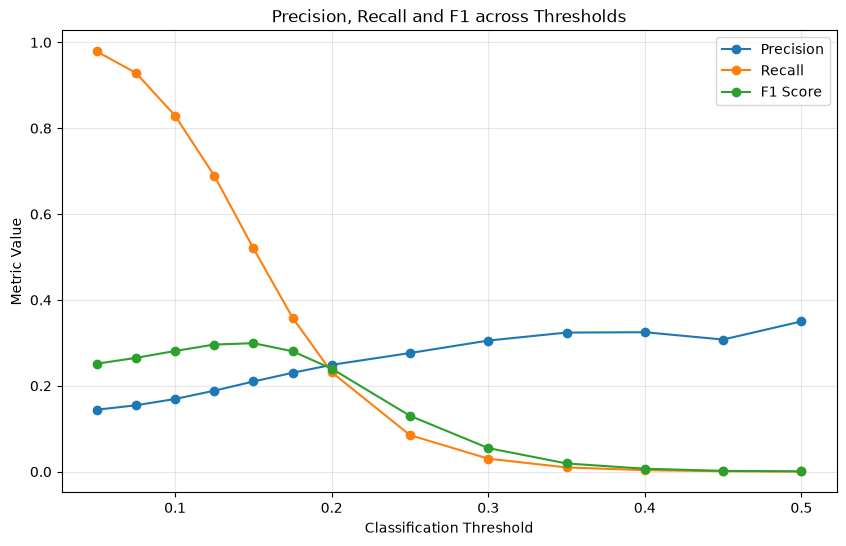

In [16]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Metric Value")
plt.title("Precision, Recall and F1 across Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

selecting threshhold = 0.15
our aim is to flag or catch as many defaulters as possible - with high f1 score

In [17]:
# Select threshold based on validation F1
SELECTED_THRESHOLD = 0.15

val_pred_selected = (
    val_proba >= SELECTED_THRESHOLD
).astype(int)

print("Selected threshold:", SELECTED_THRESHOLD)

print("\nClassification report:")
print(
    classification_report(
        y_val,
        val_pred_selected,
        target_names=["Fully Paid", "Default"],
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_val,
        val_pred_selected
    )
)

Selected threshold: 0.15

Classification report:
              precision    recall  f1-score   support

  Fully Paid       0.90      0.69      0.78    140255
     Default       0.21      0.52      0.30     22315

    accuracy                           0.67    162570
   macro avg       0.56      0.60      0.54    162570
weighted avg       0.81      0.67      0.71    162570


Confusion matrix:
[[96580 43675]
 [10706 11609]]


	              Predicted paid	            Predicted default
Actual paid	         96,580	                      43,675
Actual default	      10,706	                  11,609

In [18]:
# Extracting coefficients and odds ratios

# Get the fitted preprocessing and Logistic Regression objects
fitted_preprocessor = (
    log_reg_pipeline.named_steps["preprocessor"]
)

fitted_lr = (
    log_reg_pipeline.named_steps["model"]
)

# Retrieve transformed feature names
feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Retrieve model coefficients
coefficients = fitted_lr.coef_[0]

# Build interpretation table
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["odds_ratio"] = np.exp(
    coef_df["coefficient"]
)

coef_df["effect"] = np.where(
    coef_df["coefficient"] > 0,
    "Higher default odds",
    "Lower default odds"
)

# Sort by absolute coefficient magnitude
coef_df["abs_coefficient"] = (
    coef_df["coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "abs_coefficient",
    ascending=False
)

display(
    coef_df.drop(
        columns=["abs_coefficient"]
    ).round(4)
)

,feature,coefficient,odds_ratio,effect
38,cat__purpose_small_business,0.6844,1.9825,Higher default odds
28,cat__purpose_credit_card,-0.4662,0.6274,Lower default odds
21,cat__emp_length_Unknown,0.4643,1.5910,Higher default odds
10,num__fico_range_low,-0.3677,0.6923,Lower default odds
40,cat__purpose_wedding,-0.3602,0.6976,Lower default odds
1,num__annual_inc,-0.3310,0.7182,Lower default odds
33,cat__purpose_major_purchase,-0.2493,0.7794,Lower default odds
29,cat__purpose_debt_consolidation,-0.2464,0.7816,Lower default odds
25,cat__home_ownership_RENT,0.2115,1.2355,Higher default odds
4,num__inq_last_6mths,0.1859,1.2043,Higher default odds


we started with 15 emperical features, afrer one hot encoding we have 41 transformed features

In [19]:
# reference category inspection

fitted_encoder = (
    log_reg_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

for feature, categories, drop_idx in zip(
    CATEGORICAL_FEATURES,
    fitted_encoder.categories_,
    fitted_encoder.drop_idx_
):
    reference_category = (
        categories[drop_idx]
        if drop_idx is not None
        else None
    )

    print(f"\nFeature: {feature}")
    print("All training categories:", categories)
    print("Reference category:", reference_category)


Feature: emp_length
All training categories: ['1 year' '10+ years' '2 years' '3 years' '4 years' '5 years' '6 years'
 '7 years' '8 years' '9 years' '< 1 year' 'Unknown']
Reference category: 1 year

Feature: home_ownership
All training categories: ['MORTGAGE' 'NONE' 'OTHER' 'OWN' 'RENT']
Reference category: MORTGAGE

Feature: verification_status
All training categories: ['Not Verified' 'Source Verified' 'Verified']
Reference category: Not Verified

Feature: purpose
All training categories: ['car' 'credit_card' 'debt_consolidation' 'educational' 'home_improvement'
 'house' 'major_purchase' 'medical' 'moving' 'other' 'renewable_energy'
 'small_business' 'vacation' 'wedding']
Reference category: car


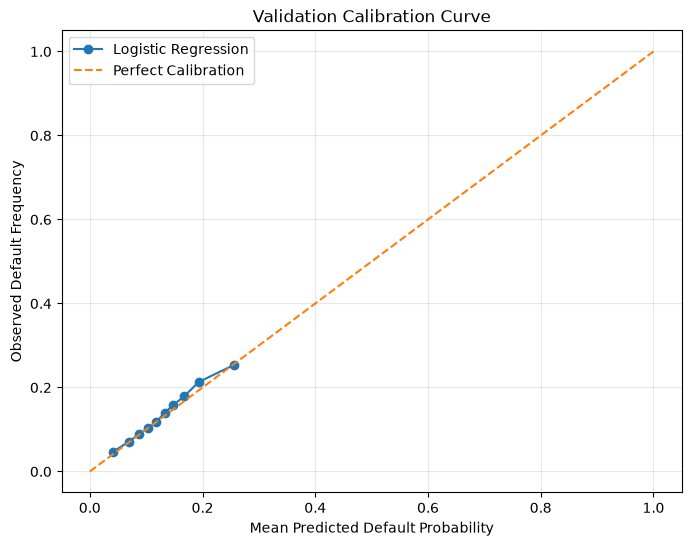

In [20]:
# probability calibration

from sklearn.calibration import calibration_curve

# Calculate calibration points using quantile bins
fraction_of_positives, mean_predicted_value = (
    calibration_curve(
        y_val,
        val_proba,
        n_bins=10,
        strategy="quantile"
    )
)

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Frequency")
plt.title("Validation Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [21]:
print(
    "Actual validation default rate:",
    f"{y_val.mean():.2%}"
)

print(
    "Mean predicted default probability:",
    f"{val_proba.mean():.2%}"
)

print(
    "Validation Brier score:",
    round(brier_score_loss(y_val, val_proba), 5)
)

print(
    "Validation log loss:",
    round(log_loss(y_val, val_proba), 5)
)

Actual validation default rate: 13.73%
Mean predicted default probability: 13.17%
Validation Brier score: 0.11464
Validation log loss: 0.38419


testing

In [22]:
# Generate default probabilities on the untouched test set
test_proba = log_reg_pipeline.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
test_pred = (
    test_proba >= SELECTED_THRESHOLD
).astype(int)

print("Final test predictions generated.")

print("Test records:", len(test_proba))
print("Actual default rate:", f"{y_test.mean():.2%}")
print("Mean predicted default probability:", f"{test_proba.mean():.2%}")
print("Selected threshold:", SELECTED_THRESHOLD)

Final test predictions generated.
Test records: 282787
Actual default rate: 14.88%
Mean predicted default probability: 12.88%
Selected threshold: 0.15


d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [23]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    brier_score_loss
)

# Discrimination metrics
test_roc_auc = roc_auc_score(y_test, test_proba)

test_ap = average_precision_score(
    y_test,
    test_proba
)

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_proba
)

test_ks = np.max(tpr - fpr)
test_gini = 2 * test_roc_auc - 1

# Probability metrics
test_log_loss = log_loss(y_test, test_proba)
test_brier = brier_score_loss(y_test, test_proba)

# Classification metrics
test_accuracy = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred, zero_division=0)
test_recall = recall_score(y_test, test_pred, zero_division=0)
test_f1 = f1_score(y_test, test_pred, zero_division=0)

print("FINAL OUT-OF-TIME TEST PERFORMANCE")
print("-" * 45)

print(f"ROC-AUC:       {test_roc_auc:.4f}")
print(f"Average Prec.: {test_ap:.4f}")
print(f"KS Statistic:  {test_ks:.4f}")
print(f"Gini:          {test_gini:.4f}")
print(f"Log Loss:      {test_log_loss:.4f}")
print(f"Brier Score:   {test_brier:.4f}")

print(f"\nAccuracy:      {test_accuracy:.4f}")
print(f"Precision:     {test_precision:.4f}")
print(f"Recall:        {test_recall:.4f}")
print(f"F1 Score:      {test_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Fully Paid", "Default"],
        zero_division=0
    )
)

FINAL OUT-OF-TIME TEST PERFORMANCE
---------------------------------------------
ROC-AUC:       0.6530
Average Prec.: 0.2349
KS Statistic:  0.2208
Gini:          0.3060
Log Loss:      0.4046
Brier Score:   0.1225

Accuracy:      0.6757
Precision:     0.2293
Recall:        0.4994
F1 Score:      0.3143

Confusion Matrix:
[[170048  70650]
 [ 21069  21020]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.89      0.71      0.79    240698
     Default       0.23      0.50      0.31     42089

    accuracy                           0.68    282787
   macro avg       0.56      0.60      0.55    282787
weighted avg       0.79      0.68      0.72    282787



In [24]:
comparison_df = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Average Precision",
        "KS",
        "Gini",
        "Log Loss",
        "Brier Score",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Validation": [
        roc_auc,
        pr_auc,
        ks_statistic,
        gini,
        val_log_loss,
        val_brier,
        precision_score(y_val, val_pred_selected),
        recall_score(y_val, val_pred_selected),
        f1_score(y_val, val_pred_selected)
    ],
    "Test": [
        test_roc_auc,
        test_ap,
        test_ks,
        test_gini,
        test_log_loss,
        test_brier,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(comparison_df.round(4))

,Metric,Validation,Test
0,ROC-AUC,0.6494,0.6530
1,Average Precision,0.2148,0.2349
2,KS,0.2198,0.2208
3,Gini,0.2988,0.3060
4,Log Loss,0.3842,0.4046
5,Brier Score,0.1146,0.1225
6,Precision,0.2100,0.2293
7,Recall,0.5202,0.4994
8,F1 Score,0.2992,0.3143


In [25]:
# benchmarking against a constant baseline

# Constant benchmark: training-set default rate
test_baseline_proba = np.full(
    len(y_test),
    y_train.mean()
)

print("TRAINING-BASED CONSTANT BASELINE")
print("-" * 40)

print(
    "Training default rate:",
    f"{y_train.mean():.2%}"
)

print(
    "Model Log Loss:",
    round(log_loss(y_test, test_proba), 5)
)

print(
    "Baseline Log Loss:",
    round(log_loss(y_test, test_baseline_proba), 5)
)

print(
    "Model Brier Score:",
    round(brier_score_loss(y_test, test_proba), 5)
)

print(
    "Baseline Brier Score:",
    round(brier_score_loss(y_test, test_baseline_proba), 5)
)


# Check unseen test categories
print("\nUNSEEN CATEGORICAL VALUES")
print("-" * 40)

for col in CATEGORICAL_FEATURES:
    train_categories = set(
        X_train[col].dropna().astype(str).unique()
    )

    test_categories = set(
        X_test[col].dropna().astype(str).unique()
    )

    unseen = test_categories - train_categories

    print(f"\n{col}: {unseen}")

    for category in unseen:
        count = (
            X_test[col].astype(str) == category
        ).sum()

        print(f"  {category}: {count} records")

TRAINING-BASED CONSTANT BASELINE
----------------------------------------
Training default rate: 12.43%
Model Log Loss: 0.40459
Baseline Log Loss: 0.4233
Model Brier Score: 0.12251
Baseline Brier Score: 0.12728

UNSEEN CATEGORICAL VALUES
----------------------------------------

emp_length: set()

home_ownership: {'ANY'}
  ANY: 1 records

verification_status: set()

purpose: set()



# Final Model Findings

## Model
L2-regularized Logistic Regression with:
- 15 original predictor features
- Median imputation for numerical variables
- StandardScaler for numerical variables
- One-hot encoding for categorical variables
- Classification threshold of 0.15, selected based on the highest F1 among the thresholds evaluated on validation data

## Evaluation Strategy
- Training: 2007–2013
- Validation: 2014
- Out-of-time test: 2015

The test dataset was held out during model development and threshold selection.

## Final Out-of-Time Results

| Metric | Validation | Test |
|---|---:|---:|
| ROC-AUC | 0.6494 | 0.6530 |
| Average Precision | 0.2148 | 0.2349 |
| KS | 0.2198 | 0.2208 |
| Gini | 0.2988 | 0.3060 |
| Log Loss | 0.3842 | 0.4046 |
| Brier Score | 0.1146 | 0.1225 |
| Precision | 0.2100 | 0.2293 |
| Recall | 0.5202 | 0.4994 |
| F1 | 0.2992 | 0.3143 |

## Key Findings

1. Discrimination remained relatively stable across validation and out-of-time test cohorts.
2. Probability quality deteriorated somewhat on the test cohort.
3. Mean predicted default probability was 12.88%, compared with an observed default rate of 14.88%.
4. The model outperformed a constant training-default-rate benchmark on both Log Loss and Brier Score.
5. Threshold selection substantially improved default detection compared with the conventional 0.5 threshold.

## Limitations

- LendingClub data represents peer-to-peer lending rather than a bank's complete loan portfolio.
- Charged-off status is used as an adverse-outcome proxy, not a formally established regulatory default definition.
- Accepted and mature loans only are included, introducing potential selection and maturity biases.
- The baseline focuses exclusively on 36-month loans.
- Predictive discrimination is modest.
- Probability calibration requires further investigation.
- Formal statistical inference, comprehensive population stability analysis and production monitoring have not been completed.
- This project is not a production-ready regulatory PD model or a complete CECL/CCAR implementation.


In [26]:
# save the model lol
import joblib

# Create models directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "logistic_regression_baseline.joblib"

# Package model and metadata
model_artifact = {
    "pipeline": log_reg_pipeline,
    "model_features": MODEL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target": TARGET,
    "threshold": SELECTED_THRESHOLD,
    "training_period": "2007-2013",
    "validation_period": "2014",
    "test_period": "2015"
}

# Save artifact
joblib.dump(
    model_artifact,
    MODEL_PATH,
    compress=3
)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: d:\M_Tech_IIITB\Projects\Data-Analysis\credit-risk-analytics\models\logistic_regression_baseline.joblib


In [27]:
saved_artifact = joblib.load(MODEL_PATH)

print("Pipeline:", type(saved_artifact["pipeline"]).__name__)
print("Threshold:", saved_artifact["threshold"])
print("Features:", len(saved_artifact["model_features"]))
print("Model path exists:", MODEL_PATH.exists())

Pipeline: Pipeline
Threshold: 0.15
Features: 15
Model path exists: True
